# Módulo 17 — Hull-White I: medidas, o modelo e as fórmulas fechadas

**Curso:** Derivativos com Python. Módulo complementar ao livro de Hilpisch, construído a partir do material de renda fixa (Wilmott, *Paul Wilmott Introduces Quantitative Finance*, caps. sobre taxas; Clewlow e Strickland, *Implementing Derivatives Models*, caps. 7 a 9; Hull e White, 1990, 1993, 1994).

## O que você vai conseguir fazer ao final

1. Trocar de numerário (conta remunerada, título zero-cupom) e saber qual esperança calcula qual preço.
2. Deduzir a solução do modelo de Hull-White e a fórmula afim do título zero-cupom.
3. Escolher $\theta(t)$ para que o modelo reproduza exatamente a curva de juros de hoje.
4. Simular o modelo **sem erro de discretização**, inclusive a integral da taxa curta.
5. Deduzir e aplicar a fórmula fechada da opção sobre título (Jamshidian) e precificar caps e floors.
6. Calibrar $a$ e $\sigma$ a volatilidades de caps, e estimar $\sigma$ a partir de séries históricas sem cair em armadilhas de anualização.

## Onde estamos

O livro de Hilpisch trata os juros como coadjuvantes: o CIR entra no BCC97 só para descontar (Módulos 11 e 13). Este módulo e o próximo colocam a taxa de juros no centro. O Hull-White é o modelo de taxa curta mais usado em mesas e em validação de modelos: é gaussiano, tem fórmulas fechadas, ajusta a curva de hoje por construção e tem uma árvore trinomial eficiente, que é o tema do Módulo 18.

| Notação aqui (Hull) | Wilmott | Clewlow-Strickland e planilha |
|---|---|---|
| $dr = (\theta(t) - a\,r)\,dt + \sigma\,dW$ | $dr = (\eta(t) - \gamma r)\,dt + c\,dX$ | $dr = (\theta(t) - \alpha r)\,dt + \sigma\,dz$ |
| $a$: velocidade de reversão | $\gamma$ | $\alpha$ (célula "alpha") |
| $\sigma$: volatilidade normal da taxa | $c$ | $\sigma$ (célula "vol") |

## 0. Preparação

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, least_squares
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def carregar_treasury():
    """Taxas diárias dos T-bills (U.S. Treasury, domínio público), as mesmas da planilha HW_arvore_final."""
    local = Path("dados/treasury_bills_2023_2024.csv")
    fonte = local if local.exists() else "https://raw.githubusercontent.com/walterCNeto/XRiscs/main/dados/treasury_bills_2023_2024.csv"
    return pd.read_csv(fonte, parse_dates=["data"])


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. A curva de juros em uma página

**Material: Aula 1 (Fixed Income Products and Analysis)**

Três objetos descrevem a mesma informação:

* o preço do título zero-cupom $P(0, T)$, que paga 1 em $T$;
* a taxa (yield) contínua $y(T) = -\ln P(0, T)/T$;
* a taxa a termo instantânea $f(0, T) = -\partial_T\ln P(0, T)$, que satisfaz $P(0, T) = e^{-\int_0^Tf(0, u)\,du}$ e $f = y + T\,y'$ (Módulo 13).

Para os laboratórios, a curva de mercado sintética é uma **Nelson-Siegel** para a taxa a termo:

$$f(0, t) = \beta_0 + \beta_1e^{-t/\tau} + \beta_2\,\frac t\tau\,e^{-t/\tau}.$$

A integral e a derivada são fechadas, o que permite conferir cada fórmula do Hull-White sem erro de interpolação. Escolhemos uma curva positivamente inclinada com uma corcova: $\beta_0 = 4{,}5\%$, $\beta_1 = -1\%$, $\beta_2 = 2\%$, $\tau = 1{,}5$.

### Laboratório 1 — A curva sintética

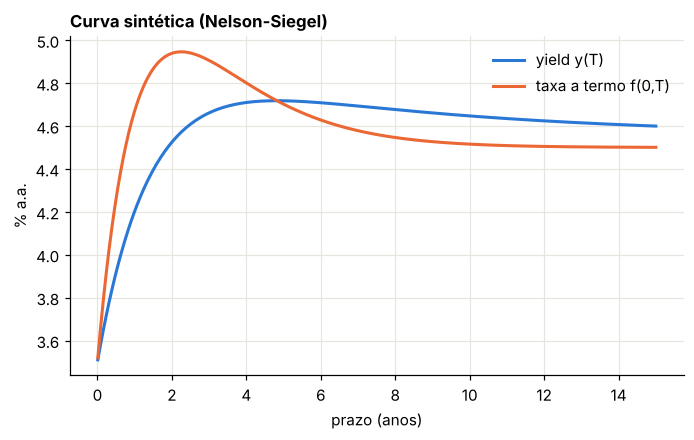

OK — f = y + T·y' (a relação da Seção 1)
OK — a integral fechada é coerente com a taxa a termo


In [2]:
NS = dict(b0=0.045, b1=-0.010, b2=0.020, tau=1.5)


def f_merc(t, b0=NS["b0"], b1=NS["b1"], b2=NS["b2"], tau=NS["tau"]):
    e = np.exp(-np.asarray(t, float) / tau)
    return b0 + b1 * e + b2 * (np.asarray(t, float) / tau) * e


def df_merc(t, b0=NS["b0"], b1=NS["b1"], b2=NS["b2"], tau=NS["tau"]):
    """Derivada ∂f(0,t)/∂t."""
    t = np.asarray(t, float); e = np.exp(-t / tau)
    return -b1 / tau * e + b2 / tau * e * (1 - t / tau)


def P_merc(T, b0=NS["b0"], b1=NS["b1"], b2=NS["b2"], tau=NS["tau"]):
    T = np.asarray(T, float); e = np.exp(-T / tau)
    integral = b0 * T + b1 * tau * (1 - e) + b2 * tau * (1 - (1 + T / tau) * e)
    return np.exp(-integral)


Tg = np.linspace(0.01, 15, 400)
y = -np.log(P_merc(Tg)) / Tg
h = 1e-5
y_der = (-np.log(P_merc(Tg + h)) / (Tg + h) + np.log(P_merc(Tg - h)) / (Tg - h)) / (2 * h)

fig, ax = plt.subplots()
ax.plot(Tg, 100 * y, color=AZUL, label="yield y(T)")
ax.plot(Tg, 100 * f_merc(Tg), color=LARANJA, label="taxa a termo f(0,T)")
ax.set_xlabel("prazo (anos)"); ax.set_ylabel("% a.a."); ax.set_title("Curva sintética (Nelson-Siegel)")
ax.legend(); plt.show()

ok(np.allclose(f_merc(Tg), y + Tg * y_der, atol=1e-8), "f = y + T·y' (a relação da Seção 1)")
num = (np.log(P_merc(Tg - h)) - np.log(P_merc(Tg + h))) / (2 * h)
ok(np.allclose(num, f_merc(Tg), atol=1e-8), "a integral fechada é coerente com a taxa a termo")

---
## 2. Numerários e medidas

**Material: Aula 2 (Martingales & Measures) e Aula 3 (Standard Model)**

### 2.1 O preço de mercado do risco

Seja $\theta$ uma variável de estado com $d\theta/\theta = m\,dt + s\,dZ$, e $f_1, f_2$ dois derivativos que dependem só de $\theta$: $df_i/f_i = \mu_i\,dt + \sigma_i\,dZ$. A carteira $\Pi = (\sigma_2f_2)f_1 - (\sigma_1f_1)f_2$ elimina $dZ$, logo rende $r$:

$$(\sigma_2\mu_1 - \sigma_1\mu_2)\,\Delta t = r(\sigma_2 - \sigma_1)\,\Delta t \quad\Longrightarrow\quad \frac{\mu_1 - r}{\sigma_1} = \frac{\mu_2 - r}{\sigma_2} \equiv \lambda.$$

$\lambda$ é o **preço de mercado do risco** de $\theta$: o mesmo para todos os derivativos dessa fonte de incerteza. Escolher um valor de $\lambda$ é escolher um "mundo": com $\lambda = 0$, todos rendem $r$ (o mundo neutro ao risco tradicional); com $\lambda = \sigma_g$, a volatilidade de um ativo $g$, todos os preços **relativos** $f/g$ viram martingais.

### 2.2 O resultado da medida martingal equivalente

Com $\lambda = \sigma_g$, Itô em $\ln(f/g)$ dá $d(f/g) = (\sigma_f - \sigma_g)(f/g)\,dZ$: sem drift. Logo

$$\frac{f_0}{g_0} = \mathbb{E}^g\Big[\frac{f_T}{g_T}\Big] \quad\Longrightarrow\quad f_0 = g_0\,\mathbb{E}^g\Big[\frac{f_T}{g_T}\Big].$$

Duas escolhas de numerário $g$ dominam a renda fixa:

| Numerário $g$ | $g_0$, $g_T$ | Fórmula de preço | Medida |
|---|---|---|---|
| conta remunerada | $1$, $e^{\int_0^Tr\,du}$ | $f_0 = \mathbb{E}^Q\big[e^{-\int_0^Tr\,du}f_T\big]$ | neutra ao risco $Q$ |
| zero-cupom $P(t, T)$ | $P(0, T)$, $1$ | $f_0 = P(0, T)\,\mathbb{E}^T[f_T]$ | a termo em $T$ |

A segunda é a base do modelo de Black (Aula 3): sob a medida a termo, o **preço a termo** de qualquer ativo é martingal, e o desconto sai da esperança, mesmo com juros estocásticos.

### 2.3 Como fica o Hull-White sob cada medida

Sob $Q$: $dr = (\theta(t) - a\,r)\,dt + \sigma\,dW^Q$. Pelo teorema de Girsanov (Módulo 4), passar à medida a termo em $T$ acrescenta ao drift o produto da volatilidade de $r$ pela volatilidade do numerário $P(t, T)$, que no Hull-White é $-\sigma B(t, T)$ (Seção 3):

$$dr = \big(\theta(t) - a\,r - \sigma^2B(t, T)\big)\,dt + \sigma\,dW^T, \qquad B(t, T) = \frac{1 - e^{-a(T - t)}}{a}.$$

Sob a medida a termo, a taxa tem drift **menor**: os estados de juros altos, em que o numerário $P(t, T)$ vale pouco, ganham menos peso. O Laboratório 3 confere que as duas medidas dão o mesmo preço.

---
## 3. O modelo de Hull-White

**Material: Aula 4 (Stochastic Interest Rate Modeling) e Aula 5 (Calibration and Data Analysis)**

### 3.1 De Vasicek a Hull-White

* **Vasicek** (1977): $dr = (\eta - a\,r)\,dt + \sigma\,dW$. Reversão à média, taxa normal, fórmulas fechadas. Mas com três parâmetros constantes não reproduz a curva de hoje.
* **Ho-Lee** (1986): $dr = \eta(t)\,dt + \sigma\,dW$. O drift dependente do tempo ajusta a curva, mas não há reversão: a variância de $r$ cresce sem limite.
* **Hull-White** (1990), o "Vasicek estendido": $dr = (\theta(t) - a\,r)\,dt + \sigma\,dW$. Junta os dois: reversão e ajuste exato da curva.

### 3.2 A solução, passo a passo

**Passo 1.** Multiplique por $e^{at}$: $d(e^{at}r) = e^{at}\theta(t)\,dt + \sigma e^{at}\,dW$.

**Passo 2.** Integre de $s$ a $t$:

$$r(t) = r(s)\,e^{-a(t - s)} + \int_s^t e^{-a(t - u)}\theta(u)\,du + \sigma\int_s^te^{-a(t - u)}\,dW(u).$$

**Passo 3.** A integral estocástica de um integrando determinístico é normal, com média zero e variância (isometria de Itô) $\sigma^2\int_s^te^{-2a(t - u)}du = \frac{\sigma^2}{2a}(1 - e^{-2a(t - s)})$. Logo $r(t)$ é **normal**: pode ficar negativa, com probabilidade calculável.

### 3.3 O título zero-cupom: a forma afim

Pelo argumento de hedge da Seção 2.1, $V(r, t)$ satisfaz a EDP de precificação

$$\frac{\partial V}{\partial t} + \tfrac12\sigma^2\frac{\partial^2V}{\partial r^2} + (\theta(t) - a\,r)\frac{\partial V}{\partial r} - rV = 0, \qquad V(r, T) = 1.$$

Tente $P = e^{A(t) - rB(t)}$, como no CIR (Módulo 11). Substituindo e dividindo por $P$:

$$\dot A - r\dot B + \tfrac12\sigma^2B^2 - (\theta - a\,r)B - r = 0.$$

O termo em $r$ e o termo sem $r$ se anulam separadamente:

$$\dot B = aB - 1,\ B(T) = 0 \;\Rightarrow\; B(t, T) = \frac{1 - e^{-a(T - t)}}{a}; \qquad \dot A = \theta B - \tfrac12\sigma^2B^2,\ A(T) = 0.$$

### 3.4 Ajustar a curva: a escolha de $\theta(t)$

Queremos que o modelo devolva $P(0, T) = P^{mkt}(0, T)$ para todo $T$. Em termos de taxas a termo, a condição é $f^{modelo}(0, T) = f^{mkt}(0, T)$. Escrevendo $r(t) = x(t) + \varphi(t)$, com $x$ o OU que parte de zero, $dx = -a\,x\,dt + \sigma\,dW$, e $\varphi$ determinística, a condição de ajuste é (Brigo e Mercurio, cap. 3)

$$\varphi(t) = f^{mkt}(0, t) + \frac{\sigma^2}{2a^2}\big(1 - e^{-at}\big)^2.$$

Derivando $r = x + \varphi$ e comparando com a EDS, $\theta(t) = \varphi'(t) + a\,\varphi(t)$:

$$\boxed{\theta(t) = \frac{\partial f^{mkt}(0, t)}{\partial t} + a\,f^{mkt}(0, t) + \frac{\sigma^2}{2a}\big(1 - e^{-2at}\big).}$$

Com $\theta$ assim, o preço do título em $t > 0$ fica escrito só com a curva de hoje:

$$P(t, T) = \frac{P^{mkt}(0, T)}{P^{mkt}(0, t)}\exp\Big(B(t, T)\,f^{mkt}(0, t) - \frac{\sigma^2}{4a}\big(1 - e^{-2at}\big)B(t, T)^2 - B(t, T)\,r(t)\Big).$$

### 3.5 Simular sem erro de discretização

Como tudo é gaussiano, o par ($x$ no fim do passo, integral de $x$ no passo) tem lei conhecida. Num passo de tamanho $\Delta$:

$$x_{t + \Delta} = x_te^{-a\Delta} + \varepsilon_1, \qquad \int_t^{t + \Delta}x\,du = x_t\,B(\Delta) + \varepsilon_2,$$

com $(\varepsilon_1, \varepsilon_2)$ normal bivariada de média zero,

$$\text{Var}\,\varepsilon_1 = \frac{\sigma^2}{2a}(1 - e^{-2a\Delta}), \quad \text{Var}\,\varepsilon_2 = \frac{\sigma^2}{a^2}\Big(\Delta - 2B(\Delta) + \frac{1 - e^{-2a\Delta}}{2a}\Big), \quad \text{Cov} = \frac{\sigma^2}{2a^2}(1 - e^{-a\Delta})^2.$$

A integral de $r$ é a de $x$ mais $\int\varphi$, que é fechada para a curva Nelson-Siegel. Nenhuma aproximação de Euler: o único erro do Monte Carlo é estatístico.

### Laboratório 2 — O modelo reproduz a curva

Parâmetros: $a = 0{,}1$ e $\sigma = 1\%$ ao ano (volatilidade normal, em pontos de taxa).

,T,P mercado,E[e^{−∫r}] (MC),desvio em erros-padrão,média de r(T) MC,φ(T),dp de r(T) MC,dp teórico,% r(T) < 0
0,"1,000","0,959","0,959","-0,226","0,047","0,047","0,010","0,010","0,000"
1,"2,000","0,913","0,913","-1,007","0,050","0,050","0,013","0,013","0,002"
2,"5,000","0,790","0,790","-1,424","0,048","0,048","0,018","0,018","0,376"
3,"10,000","0,628","0,628","-2,897","0,047","0,047","0,021","0,021","1,142"


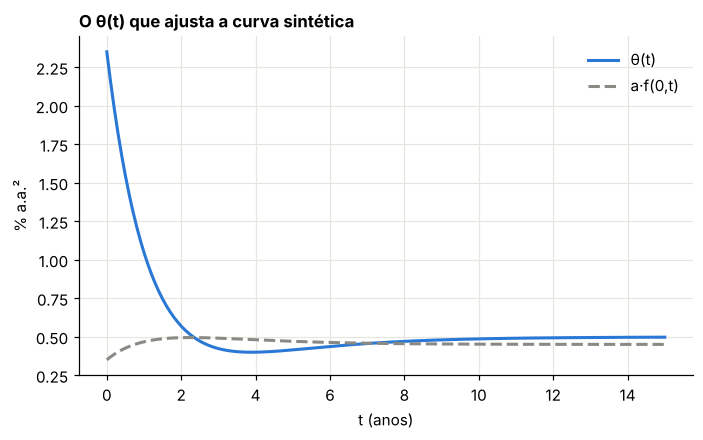

OK — o Monte Carlo exato reprecifica a curva de mercado em todos os prazos
OK — a média de r(T) é φ(T)
OK — e o desvio-padrão é o da isometria de Itô
OK — a fórmula de P(t,T) em t = 0 devolve a curva de mercado


In [3]:
A_HW, S_HW = 0.10, 0.010


def B_hw(tau, a=A_HW):
    return (1 - np.exp(-a * np.asarray(tau, float))) / a


def theta_hw(t, a=A_HW, s=S_HW):
    return df_merc(t) + a * f_merc(t) + s**2 / (2 * a) * (1 - np.exp(-2 * a * np.asarray(t, float)))


def phi_hw(t, a=A_HW, s=S_HW):
    return f_merc(t) + s**2 / (2 * a**2) * (1 - np.exp(-a * np.asarray(t, float))) ** 2


def int_phi(t0, t1, a=A_HW, s=S_HW):
    """∫ φ(u) du de t0 a t1, fechada."""
    def prim(t):
        t = np.asarray(t, float)
        return -np.log(P_merc(t)) + s**2 / (2 * a**2) * (t - 2 * (1 - np.exp(-a * t)) / a + (1 - np.exp(-2 * a * t)) / (2 * a))
    return prim(t1) - prim(t0)


def P_hw(t, T, r, a=A_HW, s=S_HW):
    """Zero-cupom em t, dado r(t), com θ ajustado à curva (Seção 3.4)."""
    B = B_hw(T - t, a)
    return P_merc(T) / P_merc(t) * np.exp(B * f_merc(t) - s**2 / (4 * a) * (1 - np.exp(-2 * a * t)) * B**2 - B * r)


def simular_hw(datas, I, rng, a=A_HW, s=S_HW, medida_T=None):
    """Simulação exata de (r, ∫r) nas datas pedidas. Com medida_T, simula sob a medida a termo em medida_T."""
    datas = np.asarray(datas, float)
    x = np.zeros(I); integ = np.zeros(I); t = 0.0
    rs, Is = [], []
    for t1 in datas:
        d = t1 - t
        e1 = np.exp(-a * d)
        v1 = s**2 / (2 * a) * (1 - e1**2)
        v2 = s**2 / a**2 * (d - 2 * (1 - e1) / a + (1 - e1**2) / (2 * a))
        c12 = s**2 / (2 * a**2) * (1 - e1) ** 2
        L = np.linalg.cholesky(np.array([[v1, c12], [c12, v2]]))
        z = L @ rng.standard_normal((2, I))
        m1, m2 = 0.0, 0.0
        if medida_T is not None:
            # drift extra −σ²B(u,T) integrado exatamente no passo
            k = lambda u: -(s**2 / a) * (1 - np.exp(-a * (medida_T - u)))
            us = np.linspace(t, t1, 201)
            m1 = np.trapezoid(k(us) * np.exp(-a * (t1 - us)), us)
            m2 = np.trapezoid(k(us) * (1 - np.exp(-a * (t1 - us))) / a, us)
        integ = integ + x * (1 - e1) / a + z[1] + m2
        x = x * e1 + z[0] + m1
        rs.append(x + phi_hw(t1, a, s)); Is.append(integ + int_phi(0, t1, a, s))
        t = t1
    return np.array(rs), np.array(Is)


rng = np.random.default_rng(17)
Ts = np.array([1.0, 2.0, 5.0, 10.0])
r_sim, I_sim = simular_hw(Ts, 200_000, rng)
desc = np.exp(-I_sim)
linhas = []
for k, T in enumerate(Ts):
    est = desc[k].mean(); ep = desc[k].std() / np.sqrt(desc.shape[1])
    linhas.append((T, P_merc(T), est, (est - P_merc(T)) / ep, r_sim[k].mean(), phi_hw(T), r_sim[k].std(),
                   S_HW * np.sqrt((1 - np.exp(-2 * A_HW * T)) / (2 * A_HW)), 100 * np.mean(r_sim[k] < 0)))
tab2 = pd.DataFrame(linhas, columns=["T", "P mercado", "E[e^{−∫r}] (MC)", "desvio em erros-padrão",
                                     "média de r(T) MC", "φ(T)", "dp de r(T) MC", "dp teórico", "% r(T) < 0"])
tabela(tab2)

fig, ax = plt.subplots()
tt = np.linspace(0, 15, 300)
ax.plot(tt, 100 * theta_hw(tt), color=AZUL, label="θ(t)")
ax.plot(tt, 100 * A_HW * f_merc(tt), "--", color=CINZA, label="a·f(0,t)")
ax.set_xlabel("t (anos)"); ax.set_ylabel("% a.a.²"); ax.set_title("O θ(t) que ajusta a curva sintética")
ax.legend(); plt.show()

ok(np.all(np.abs(tab2["desvio em erros-padrão"]) < 4), "o Monte Carlo exato reprecifica a curva de mercado em todos os prazos")
ok(np.allclose(tab2["média de r(T) MC"], tab2["φ(T)"], atol=4e-4), "a média de r(T) é φ(T)")
ok(np.allclose(tab2["dp de r(T) MC"], tab2["dp teórico"], rtol=0.01), "e o desvio-padrão é o da isometria de Itô")
ok(abs(np.log(P_hw(0.0, 7.0, f_merc(0.0)) / P_merc(7.0))) < 1e-12, "a fórmula de P(t,T) em t = 0 devolve a curva de mercado")

O modelo reprecifica a curva com erro dentro do ruído estatístico, como manda a construção. Repare também na última coluna: com $\sigma = 1\%$ e a curva em torno de 4,5%, cerca de 1 em cada 100 cenários de 10 anos tem taxa negativa; com a curva perto de zero, como na Europa de 2015 a 2021, seriam quase metade. Em ambientes de juros baixos isso é um defeito; em outros, uma propriedade aceitável.

### Laboratório 3 — A mesma opção sob duas medidas

Uma call europeia com vencimento $T = 1$ sobre o zero-cupom que vence em $S = 5$, com strike igual ao preço a termo, $K = P(0, S)/P(0, T)$. Pela Seção 2.2, devemos ter

$$\mathbb{E}^Q\big[e^{-\int_0^Tr}\,(P(T, S) - K)^+\big] = P(0, T)\,\mathbb{E}^T\big[(P(T, S) - K)^+\big].$$

Também conferimos a fórmula fechada de $P(t, T)$ por um Monte Carlo **condicional**: partindo de três valores de $r(1)$, simulamos de 1 a 5 anos e comparamos $\mathbb{E}[e^{-\int_1^5r}\,|\,r(1)]$ com a fórmula.

In [4]:
T_op, S_op = 1.0, 5.0
K_atm = P_merc(S_op) / P_merc(T_op)

rng = np.random.default_rng(3)
rQ, IQ = simular_hw([T_op], 400_000, rng)
pay_Q = np.exp(-IQ[0]) * np.maximum(P_hw(T_op, S_op, rQ[0]) - K_atm, 0)
rT, _ = simular_hw([T_op], 400_000, rng, medida_T=T_op)
pay_T = P_merc(T_op) * np.maximum(P_hw(T_op, S_op, rT[0]) - K_atm, 0)
print("call sob Q:", f3(1e4 * pay_Q.mean()), "pb | sob a medida a termo:", f3(1e4 * pay_T.mean()), "pb (por unidade de face)")
print("E^T[P(T,S)] =", f"{P_hw(T_op, S_op, rT[0]).mean():.6f}", "| preço a termo P(0,S)/P(0,T) =", f"{K_atm:.6f}")

ep_Q = pay_Q.std() / np.sqrt(len(pay_Q)); ep_T = pay_T.std() / np.sqrt(len(pay_T))
ok(abs(pay_Q.mean() - pay_T.mean()) < 4 * np.hypot(ep_Q, ep_T), "as duas medidas dão o mesmo preço, a menos do ruído")
ok(abs(P_hw(T_op, S_op, rT[0]).mean() / K_atm - 1) < 2e-4, "sob a medida a termo, o preço a termo do título é martingal")
ok(rT[0].mean() < rQ[0].mean(), "e a taxa curta tem drift menor sob a medida a termo")

# P(t,T) por Monte Carlo condicional
linhas = []
rng = np.random.default_rng(5)
for r1 in [0.0, phi_hw(1.0), 0.08]:
    x1 = r1 - phi_hw(1.0)
    # simula x de 1 a 5 a partir de x1, com passos exatos
    x = np.full(100_000, x1); integ = np.zeros_like(x); t = 1.0
    for t1 in np.linspace(1.0, 5.0, 41)[1:]:
        d = t1 - t; e1 = np.exp(-A_HW * d)
        v1 = S_HW**2 / (2 * A_HW) * (1 - e1**2)
        v2 = S_HW**2 / A_HW**2 * (d - 2 * (1 - e1) / A_HW + (1 - e1**2) / (2 * A_HW))
        c12 = S_HW**2 / (2 * A_HW**2) * (1 - e1) ** 2
        z = np.linalg.cholesky([[v1, c12], [c12, v2]]) @ rng.standard_normal((2, len(x)))
        integ += x * (1 - e1) / A_HW + z[1]; x = x * e1 + z[0]; t = t1
    est = np.exp(-(integ + int_phi(1.0, 5.0))).mean()
    linhas.append((100 * r1, P_hw(1.0, 5.0, r1), est))
tab3 = pd.DataFrame(linhas, columns=["r(1) (%)", "P(1,5) fórmula", "P(1,5) Monte Carlo condicional"])
tabela(tab3)
ok(np.allclose(tab3["P(1,5) fórmula"], tab3["P(1,5) Monte Carlo condicional"], rtol=5e-4), "a fórmula afim de P(t,T) confere com a esperança condicional")

call sob Q: 98,788 pb | sob a medida a termo: 98,735 pb (por unidade de face)
E^T[P(T,S)] = 0.823765 | preço a termo P(0,S)/P(0,T) = 0.823767
OK — as duas medidas dão o mesmo preço, a menos do ruído
OK — sob a medida a termo, o preço a termo do título é martingal
OK — e a taxa curta tem drift menor sob a medida a termo


,r(1) (%),"P(1,5) fórmula","P(1,5) Monte Carlo condicional"
0,"0,000","0,960","0,961"
1,"4,676","0,823","0,823"
2,"8,000","0,738","0,738"


OK — a fórmula afim de P(t,T) confere com a esperança condicional


---
## 4. Opções sobre títulos: a fórmula de Jamshidian

**Material: Aula 3 (modelo de Black para opções sobre títulos) e planilha, aba "opcao sobre bond"**

### 4.1 Dedução pela medida a termo

**Passo 1.** Pela Seção 2.2 com numerário $P(t, T)$: $c_0 = P(0, T)\,\mathbb{E}^T[(P(T, S) - K)^+]$.

**Passo 2.** O preço a termo $F(t) = P(t, S)/P(t, T)$ é martingal sob a medida a termo. Pela forma afim, $\ln F$ é afim em $r$, e sua volatilidade é determinística:

$$\frac{dF}{F} = -\sigma\big[B(t, S) - B(t, T)\big]\,dW^T.$$

**Passo 3.** Então $\ln F(T)$ é normal, e $F(T) = P(T, S)$ (porque $P(T, T) = 1$). A variância acumulada é

$$\sigma_P^2 = \sigma^2\int_0^T\big[B(t, S) - B(t, T)\big]^2dt \quad\Longrightarrow\quad \sigma_P = \frac\sigma a\big(1 - e^{-a(S - T)}\big)\sqrt{\frac{1 - e^{-2aT}}{2a}}.$$

**Passo 4.** É o modelo de Black (Aula 3) com volatilidade integrada $\sigma_P$:

$$\boxed{\;c_0 = P(0, S)\,N(h) - K\,P(0, T)\,N(h - \sigma_P), \qquad h = \frac{1}{\sigma_P}\ln\frac{P(0, S)}{K\,P(0, T)} + \frac{\sigma_P}{2},\;}$$

e a put, por paridade: $p_0 = K\,P(0, T)\,N(-h + \sigma_P) - P(0, S)\,N(-h)$.

### Laboratório 4 — Fórmula, Monte Carlo e a aba da planilha

In [5]:
def sigma_P(T, S, a=A_HW, s=S_HW):
    return s / a * (1 - np.exp(-a * (S - T))) * np.sqrt((1 - np.exp(-2 * a * T)) / (2 * a))


def zbc(T, S, K, PT, PS, a=A_HW, s=S_HW):
    sp = sigma_P(T, S, a, s)
    h_ = np.log(PS / (K * PT)) / sp + sp / 2
    return PS * norm.cdf(h_) - K * PT * norm.cdf(h_ - sp)


def zbp(T, S, K, PT, PS, a=A_HW, s=S_HW):
    sp = sigma_P(T, S, a, s)
    h_ = np.log(PS / (K * PT)) / sp + sp / 2
    return K * PT * norm.cdf(-h_ + sp) - PS * norm.cdf(-h_)


linhas = []
for K in [0.95 * K_atm, K_atm, 1.05 * K_atm]:
    formula = zbc(T_op, S_op, K, P_merc(T_op), P_merc(S_op))
    mc = (np.exp(-IQ[0]) * np.maximum(P_hw(T_op, S_op, rQ[0]) - K, 0))
    put = zbp(T_op, S_op, K, P_merc(T_op), P_merc(S_op))
    linhas.append((K, 1e4 * formula, 1e4 * mc.mean(), 1e4 * mc.std() / np.sqrt(len(mc)),
                   1e4 * (formula - put - (P_merc(S_op) - K * P_merc(T_op)))))
tab4 = pd.DataFrame(linhas, columns=["strike", "call fórmula (pb)", "call MC (pb)", "erro-padrão (pb)", "paridade (pb)"])
tabela(tab4)
print("σ_P =", f3(100 * sigma_P(T_op, S_op)), "% (volatilidade integrada do preço a termo)")
ok(np.all(np.abs(tab4["call fórmula (pb)"] - tab4["call MC (pb)"]) < 4 * tab4["erro-padrão (pb)"]), "Jamshidian confere com o Monte Carlo exato")
ok(np.all(np.abs(tab4["paridade (pb)"]) < 1e-9), "paridade put-call vale exatamente")

,strike,call fórmula (pb),call MC (pb),erro-padrão (pb),paridade (pb)
0,"0,783","400,108","399,790","0,379","-0,000"
1,"0,824","98,897","98,788","0,234","0,000"
2,"0,865","6,567","6,546","0,057","-0,000"


σ_P = 3,139 % (volatilidade integrada do preço a termo)
OK — Jamshidian confere com o Monte Carlo exato
OK — paridade put-call vale exatamente


#### A aba "opcao sobre bond" da planilha

A planilha implementa a mesma fórmula, com $T = 0{,}25$ (3 meses), $S = 1/3$ (4 meses), $\sigma = 0{,}02464$, $a = 0{,}0527$ e $K = 0{,}9999$. Os descontos usam uma única taxa, $r = 5{,}24\%$ (a de 3 meses), para os dois prazos. Reproduzimos o resultado e mostramos o efeito de três escolhas de entrada.

In [6]:
a_pl, s_pl, T_pl, S_pl, r_pl, K_pl = 0.0527, 0.02463782739818595, 0.25, 1 / 3, 0.0524, 0.9999
PT_pl, PS_pl = np.exp(-r_pl * T_pl), np.exp(-r_pl * S_pl)
sp_pl = sigma_P(T_pl, S_pl, a_pl, s_pl)
premio_pl = zbc(T_pl, S_pl, K_pl, PT_pl, PS_pl, a_pl, s_pl)
print("planilha — σ_P:", f"{sp_pl:.7f}", "(planilha: 0,0010176) | prêmio:", f"{premio_pl:.3e}", "(planilha: 2,995e-09)")
ok(abs(sp_pl - 0.0010176144014825044) < 1e-12 and abs(premio_pl - 2.994811264221483e-09) < 1e-15, "a fórmula reproduz a planilha")

# curva da própria planilha: P(0,0,25) com 5,24% e P(0,1/3) com 5,21% (os yields das linhas 32 e 33)
PT_c, PS_c = np.exp(-0.0524 * 0.25), np.exp(-0.0521 / 3)
F_c = PS_c / PT_c
casos = [("planilha (taxa única, K = 0,9999)", PT_pl, PS_pl, K_pl),
         ("curva da planilha, K = 0,9999", PT_c, PS_c, K_pl),
         ("curva da planilha, K no dinheiro a termo", PT_c, PS_c, F_c)]
tab4b = pd.DataFrame([(n, k, ps / pt, 1e4 * zbc(T_pl, S_pl, k, pt, ps, a_pl, s_pl)) for n, pt, ps, k in casos],
                     columns=["caso", "strike", "preço a termo P(0,S)/P(0,T)", "call (pb da face)"])
tabela(tab4b)
ok(tab4b["call (pb da face)"].iloc[2] > 1e3 * tab4b["call (pb da face)"].iloc[0], "no dinheiro, a opção vale milhares de vezes mais que com K = 0,9999")

planilha — σ_P: 0.0010176 (planilha: 0,0010176) | prêmio: 2.995e-09 (planilha: 2,995e-09)
OK — a fórmula reproduz a planilha


,caso,strike,"preço a termo P(0,S)/P(0,T)",call (pb da face)
0,"planilha (taxa única, K = 0,9999)","1,000","0,996","0,000"
1,"curva da planilha, K = 0,9999","1,000","0,996","0,000"
2,"curva da planilha, K no dinheiro a termo","0,996","0,996","3,990"


OK — no dinheiro, a opção vale milhares de vezes mais que com K = 0,9999


O strike de 0,9999 está muito acima do preço a termo do título (cerca de 0,9957): a call está muito fora do dinheiro, e o prêmio de $3\times10^{-9}$ é praticamente zero. Com o strike no dinheiro a termo, a mesma fórmula dá um prêmio da ordem de alguns pontos-base da face, que é o que se espera de uma opção de 3 meses sobre um título de 4 meses.

---
## 5. Caps e floors como opções sobre títulos

**Material: Aula 3 (caps e floors)**

### 5.1 Um caplet é uma put sobre um zero-cupom

Um caplet com datas $t_k < t_{k+1}$, prazo $\delta = t_{k+1} - t_k$, principal $L$ e taxa-teto $R_K$ paga em $t_{k+1}$ o valor $L\delta\max(R_k - R_K, 0)$, em que $R_k$ é a taxa simples observada em $t_k$. Trazendo para $t_k$ (dividindo por $1 + \delta R_k$):

$$\frac{L\delta(R_k - R_K)^+}{1 + \delta R_k} = \Big(L - \frac{L(1 + \delta R_K)}{1 + \delta R_k}\Big)^+ = L(1 + \delta R_K)\Big(\frac{1}{1 + \delta R_K} - P(t_k, t_{k+1})\Big)^+.$$

É uma **put** sobre o zero-cupom de $t_{k+1}$, com vencimento $t_k$, strike $1/(1 + \delta R_K)$ e quantidade $L(1 + \delta R_K)$. No Hull-White, a fórmula da Seção 4 dá o caplet em forma fechada; o cap é a soma dos caplets, e o floor é a soma das calls correspondentes.

### 5.2 Volatilidades implícitas de Black

O mercado cota caplets pelo modelo de Black (Aula 3): $\text{caplet} = L\delta P(0, t_{k+1})\,[F_kN(d_1) - R_KN(d_2)]$, com $F_k$ a taxa a termo simples e $d_{1,2} = [\ln(F_k/R_K) \pm \sigma_k^2t_k/2]/(\sigma_k\sqrt{t_k})$. Como o Hull-White é um modelo **normal**, as vols de Black que ele implica caem com o strike: o modelo tem um "skew" embutido.

### Laboratório 5 — Caplets: fórmula, Monte Carlo e o skew implícito

,taxa-teto (%),caplet HW (pb),caplet MC (pb),erro-padrão (pb),vol de Black implícita (%)
0,"3,475","35,556","35,568","0,040","21,762"
1,"4,225","21,919","21,932","0,034","19,825"
2,"4,975","11,552","11,560","0,026","18,298"
3,"5,725","5,020","5,020","0,017","17,053"
4,"6,475","1,743","1,743","0,010","16,012"


taxa a termo F(2; 2,25) = 4,975 %


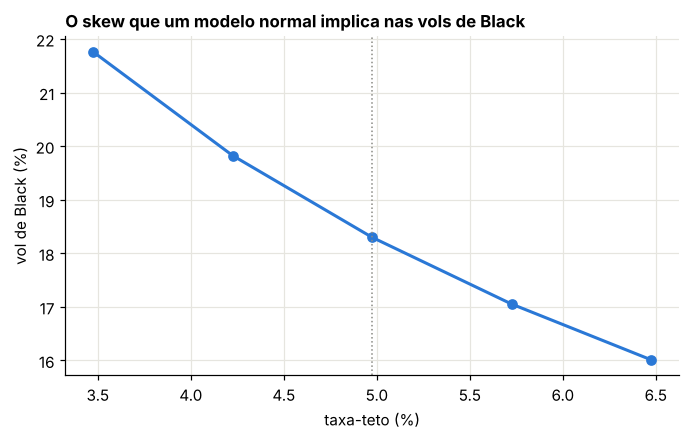

OK — o caplet como put sobre título confere com o Monte Carlo do payoff original
OK — as vols de Black implícitas pelo Hull-White caem com a taxa-teto


In [7]:
def caplet_hw(tk, delta, RK, a=A_HW, s=S_HW, L=1.0):
    Kb = 1 / (1 + delta * RK)
    return L * (1 + delta * RK) * zbp(tk, tk + delta, Kb, P_merc(tk), P_merc(tk + delta), a, s)


def caplet_black(tk, delta, RK, vol, L=1.0):
    F = (P_merc(tk) / P_merc(tk + delta) - 1) / delta
    d1 = (np.log(F / RK) + 0.5 * vol**2 * tk) / (vol * np.sqrt(tk))
    return L * delta * P_merc(tk + delta) * (F * norm.cdf(d1) - RK * norm.cdf(d1 - vol * np.sqrt(tk)))


def vol_black(preco, tk, delta, RK):
    return brentq(lambda v: caplet_black(tk, delta, RK, v) - preco, 1e-4, 3.0)


tk, delta = 2.0, 0.25
F2 = (P_merc(tk) / P_merc(tk + delta) - 1) / delta
rng = np.random.default_rng(8)
r_k, I_k = simular_hw([tk], 400_000, rng)
linhas = []
for RK in F2 + np.array([-0.015, -0.0075, 0.0, 0.0075, 0.015]):
    formula = caplet_hw(tk, delta, RK)
    Rk_sim = (1 / P_hw(tk, tk + delta, r_k[0]) - 1) / delta
    pay = np.exp(-I_k[0]) * P_hw(tk, tk + delta, r_k[0]) * delta * np.maximum(Rk_sim - RK, 0)
    linhas.append((100 * RK, 1e4 * formula, 1e4 * pay.mean(), 1e4 * pay.std() / np.sqrt(len(pay)), 100 * vol_black(formula, tk, delta, RK)))
tab5 = pd.DataFrame(linhas, columns=["taxa-teto (%)", "caplet HW (pb)", "caplet MC (pb)", "erro-padrão (pb)", "vol de Black implícita (%)"])
tabela(tab5)
print("taxa a termo F(2; 2,25) =", f3(100 * F2), "%")

fig, ax = plt.subplots()
ax.plot(tab5["taxa-teto (%)"], tab5["vol de Black implícita (%)"], "o-", color=AZUL)
ax.axvline(100 * F2, color=CINZA, ls=":", lw=1)
ax.set_xlabel("taxa-teto (%)"); ax.set_ylabel("vol de Black (%)")
ax.set_title("O skew que um modelo normal implica nas vols de Black")
plt.show()

ok(np.all(np.abs(tab5["caplet HW (pb)"] - tab5["caplet MC (pb)"]) < 4 * tab5["erro-padrão (pb)"]), "o caplet como put sobre título confere com o Monte Carlo do payoff original")
ok(np.all(np.diff(tab5["vol de Black implícita (%)"]) < 0), "as vols de Black implícitas pelo Hull-White caem com a taxa-teto")

### 5.3 Calibrar $a$ e $\sigma$ a um cap

**Material: Aula 5**

Com $\theta(t)$ fixado pela curva, sobram $a$ e $\sigma$. Eles são calibrados a opções: tipicamente, a vols de Black de caplets no dinheiro em vários vencimentos. $\sigma$ dá o nível; $a$ dá a forma da estrutura a termo das vols. Com reversão, a volatilidade da taxa de prazo longo é menor que a da curta, e as vols de caplets longos caem.

Geramos um "mercado" de vols ATM a partir de $a = 0{,}08$ e $\sigma = 0{,}9\%$, com ruído de 0,2 ponto de vol, e recuperamos os parâmetros por mínimos quadrados.

calibrado: a = 0,085 | σ = 0,911 % | verdade: a = 0,080, σ = 0,900 %


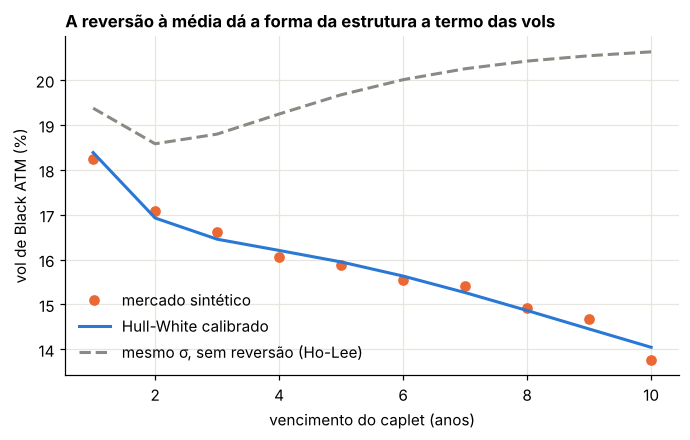

OK — a calibração recupera a e σ dentro do ruído das cotações


In [8]:
venc = np.arange(1.0, 10.01, 1.0)
A_V, S_V = 0.08, 0.009
rng = np.random.default_rng(11)


def vols_atm(a, s):
    out = []
    for t in venc:
        F = (P_merc(t) / P_merc(t + delta) - 1) / delta
        out.append(vol_black(caplet_hw(t, delta, F, a, s), t, delta, F))
    return np.array(out)


vols_merc = vols_atm(A_V, S_V) + rng.normal(0, 0.002, len(venc))
res = least_squares(lambda p: vols_atm(*p) - vols_merc, x0=[0.2, 0.012], bounds=([0.001, 0.001], [1.0, 0.05]))
a_cal, s_cal = res.x
print("calibrado: a =", f3(a_cal), "| σ =", f3(100 * s_cal), "% | verdade: a = 0,080, σ = 0,900 %")

fig, ax = plt.subplots()
ax.plot(venc, 100 * vols_merc, "o", color=LARANJA, label="mercado sintético")
ax.plot(venc, 100 * vols_atm(a_cal, s_cal), color=AZUL, label="Hull-White calibrado")
ax.plot(venc, 100 * vols_atm(0.0001, s_cal), "--", color=CINZA, label="mesmo σ, sem reversão (Ho-Lee)")
ax.set_xlabel("vencimento do caplet (anos)"); ax.set_ylabel("vol de Black ATM (%)")
ax.set_title("A reversão à média dá a forma da estrutura a termo das vols"); ax.legend(); plt.show()

ok(abs(a_cal - A_V) < 0.03 and abs(s_cal - S_V) < 0.0007, "a calibração recupera a e σ dentro do ruído das cotações")

---
## 6. Estimar $\sigma$ pela série histórica

**Material: Aula 5 (Data Analysis) e planilha, aba "daily-treasury-rates"**

### 6.1 A conta certa

No Hull-White, $\sigma$ é a volatilidade **normal** da taxa curta: num dia, $\Delta r \approx \sigma\sqrt{\Delta t}\,z$. Com variações diárias e 252 dias úteis por ano,

$$\hat\sigma = \text{dp}(\Delta r_{\text{diário}})\times\sqrt{252}.$$

A variância cresce com o tempo; o desvio-padrão, com a **raiz** do tempo.

### 6.2 O que a planilha faz

A aba "daily-treasury-rates" calcula, para o prazo de $m$ meses, a variação diária do fator $1 + R\cdot 30m/360$ e anualiza o desvio-padrão multiplicando por 252. Dois efeitos se somam:

1. **Anualização.** Multiplicar o desvio-padrão por 252, em vez de $\sqrt{252}$, aumenta o resultado em $\sqrt{252} \approx 15{,}9$ vezes.
2. **Escala do prazo.** A variação do fator é $\approx \Delta R\cdot m/12$. Para o prazo de 1 mês isso divide por 12; para 4 meses, por 3. A conta não volta para unidades de taxa.

Os dois se compensam parcialmente no prazo de 1 mês ($252/12 = 21$ contra $15{,}9$: 32% acima) e se acumulam nos prazos maiores. Por isso a "estrutura a termo de vols" da planilha **cresce** com o prazo a partir de 2 meses, de 2,1% a 3,1%, quando a vol dos T-bills, medida corretamente, **cai** com o prazo, de 1,9% a 0,6%.

### Laboratório 6 — A série dos T-bills e um teste com verdade conhecida

In [9]:
dados = carregar_treasury()
janela = dados[dados["data"] <= "2024-01-03"]
linhas = []
for col, m in [("bd_4w", 1), ("bd_8w", 2), ("bd_13w", 3), ("bd_17w", 4)]:
    Lt = janela[col].to_numpy() / 100
    fator = (1 + Lt[:-1] * 30 * m / 360) / (1 + Lt[1:] * 30 * m / 360) - 1
    vol_planilha = fator.std(ddof=1) * 252
    vol_certa = np.diff(Lt).std(ddof=1) * np.sqrt(252)
    linhas.append((f"{m} {'mês' if m == 1 else 'meses'}", 100 * vol_planilha, 100 * vol_certa, vol_planilha / vol_certa))
tab6 = pd.DataFrame(linhas, columns=["prazo", "vol da planilha (%)", "vol normal anual (%)", "razão"])
tabela(tab6)
print(f"janela: {janela['data'].iloc[0].date()} a {janela['data'].iloc[-1].date()} ({len(janela)} dias úteis)")

ok(abs(tab6["vol da planilha (%)"].iloc[0] - 2.4638) < 0.01, "a conta da planilha reproduz o vol de 2,464% do prazo de 1 mês")
ok(abs(tab6["razão"].iloc[0] - 21 / np.sqrt(252)) < 0.03, "no prazo de 1 mês, a razão é 21/√252 ≈ 1,32, como previsto")
ok(np.all(np.diff(tab6["vol da planilha (%)"].iloc[1:]) > 0) and np.all(np.diff(tab6["vol normal anual (%)"]) < 0),
   "a vol da planilha cresce com o prazo a partir de 2 meses; a vol normal cai sempre")

,prazo,vol da planilha (%),vol normal anual (%),razão
0,1 mês,"2,469","1,874","1,318"
1,2 meses,"2,140","0,815","2,625"
2,3 meses,"2,723","0,694","3,921"
3,4 meses,"3,068","0,589","5,205"


janela: 2023-01-03 a 2024-01-03 (252 dias úteis)
OK — a conta da planilha reproduz o vol de 2,464% do prazo de 1 mês
OK — no prazo de 1 mês, a razão é 21/√252 ≈ 1,32, como previsto
OK — a vol da planilha cresce com o prazo a partir de 2 meses; a vol normal cai sempre


σ estimado em 1 ano: média 0,998 % | dp 0,044 % (verdade 1,000%)
a estimado em 1 ano: mediana 4,656 | percentis 10%-90%: 0,916 a 12,790 (verdade 0,100)


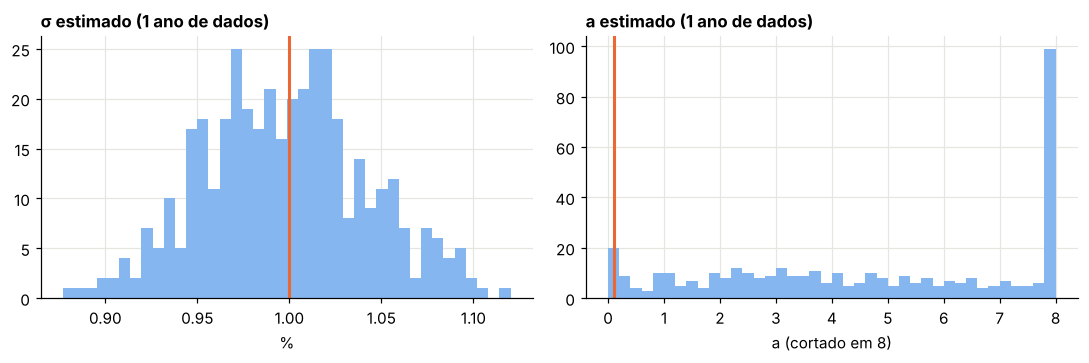

OK — a conta com √252 recupera σ sem viés
OK — com 1 ano de dados, a estimativa de a é inútil: o percentil 90% passa de 10 vezes a verdade


In [10]:
# teste com verdade conhecida: um ano de taxas diárias simuladas pelo próprio HW (a = 0,1; σ = 1%)
rng = np.random.default_rng(21)
dt = 1 / 252
n_anos = 400
est_s, est_a = [], []
for _ in range(n_anos):
    r = np.empty(253); r[0] = 0.05
    e1 = np.exp(-A_HW * dt); sd = S_HW * np.sqrt((1 - e1**2) / (2 * A_HW))
    z = rng.standard_normal(252)
    for i in range(252):
        r[i + 1] = 0.05 + (r[i] - 0.05) * e1 + sd * z[i]
    est_s.append(np.diff(r).std(ddof=1) * np.sqrt(252))
    b = np.polyfit(r[:-1], r[1:], 1)[0]                       # AR(1): r_{t+1} = c + b r_t
    est_a.append(-np.log(max(b, 1e-6)) / dt)
est_s, est_a = np.array(est_s), np.array(est_a)
print("σ estimado em 1 ano: média", f3(100 * est_s.mean()), "% | dp", f3(100 * est_s.std()), "% (verdade 1,000%)")
print("a estimado em 1 ano: mediana", f3(np.median(est_a)), "| percentis 10%-90%:", f3(np.percentile(est_a, 10)), "a", f3(np.percentile(est_a, 90)), "(verdade 0,100)")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].hist(100 * est_s, bins=40, color=RAMPA[0]); axs[0].axvline(100 * S_HW, color=LARANJA)
axs[0].set_title("σ estimado (1 ano de dados)"); axs[0].set_xlabel("%")
axs[1].hist(np.clip(est_a, 0, 8), bins=40, color=RAMPA[0]); axs[1].axvline(A_HW, color=LARANJA)
axs[1].set_title("a estimado (1 ano de dados)"); axs[1].set_xlabel("a (cortado em 8)")
plt.tight_layout(); plt.show()

ok(abs(est_s.mean() / S_HW - 1) < 0.01, "a conta com √252 recupera σ sem viés")
ok(np.percentile(est_a, 90) > 10 * A_HW, "com 1 ano de dados, a estimativa de a é inútil: o percentil 90% passa de 10 vezes a verdade")

**O que aprendemos.**

* $\sigma$ se estima bem com um ano de dados diários, desde que a anualização use $\sqrt{252}$ e a variação seja medida em unidades de taxa. Mesmo assim, num ano como 2023 (ciclo de alta do Fed), boa parte da variância das taxas curtas vem de saltos em reuniões de política monetária, não do movimento difuso que o modelo supõe.
* $a$ não se estima com um ano de dados: a reversão atua em escalas de anos ($1/a = 10$ anos aqui). Na prática, $a$ vem da calibração a opções (Seção 5.3), não da série histórica.
* Na planilha, o $a$ ("alpha") é a célula da taxa de 1 mês (0,0527). Se a intenção era um valor de referência, convém documentá-lo; se era outra célula, vale corrigir. Os dois parâmetros entram em tudo que se segue (θ, árvore e opções).

---
## 7. Ajustar a curva: a favor e contra

**Material: Aula 5 (Yield-curve fitting: for and against)**

**A favor.** O argumento de hedge exige negociar a preços de mercado. Um modelo que não reprecifica os títulos de hoje dá arbitragem contra o próprio hedge. Ajustar $\theta(t)$ é o mínimo para usar o modelo numa mesa.

**Contra.** Se o modelo estivesse certo, o $\theta(t)$ ajustado hoje continuaria valendo amanhã (deslocado no tempo). Na prática, ao reajustar uma semana depois, o $\theta$ muda muito. É a evidência de que o modelo de um fator não descreve a dinâmica da curva: ele é uma **interpolação consistente** dos preços de hoje, e não uma previsão de como a curva vai se mover.

Para validação de modelos, a conclusão prática é a do Módulo 14: o ajuste perfeito à curva e às opções de calibração não diz nada sobre o desempenho fora da amostra. É preciso acompanhar a estabilidade dos parâmetros recalibrados e o P&L do hedge.

---
## 8. Síntese

| Resultado | Fórmula | Laboratório |
|---|---|---|
| Troca de numerário | $f_0 = g_0\,\mathbb{E}^g[f_T/g_T]$ | 3 |
| Solução do HW | $r(t)$ normal, média $\varphi(t)$, variância $\frac{\sigma^2}{2a}(1 - e^{-2at})$ | 2 |
| Zero-cupom | $P = e^{A - Br}$, $B = (1 - e^{-a\tau})/a$ | 2 e 3 |
| Ajuste à curva | $\theta = f' + af + \frac{\sigma^2}{2a}(1 - e^{-2at})$ | 2 |
| Opção sobre título | Black com $\sigma_P = \frac\sigma a(1 - e^{-a(S - T)})\sqrt{\frac{1 - e^{-2aT}}{2a}}$ | 4 |
| Caplet | put sobre zero-cupom, strike $1/(1 + \delta R_K)$ | 5 |
| Estimação | $\hat\sigma = \text{dp}(\Delta r)\sqrt{252}$; $a$ vem de opções | 6 |

## 9. Notas sobre a planilha HW_arvore_final

| Onde | Observação |
|---|---|
| "HW yield", célula B23 (alpha) | $a$ aponta para a taxa de 1 mês (0,0527), não para uma estimativa de reversão; o mesmo valor alimenta a aba de opções |
| "daily-treasury-rates", linha 3 | desvio-padrão anualizado por 252, e não $\sqrt{252}$; variação do fator $1 + R\cdot 30m/360$ sem dividir por $m/12$: vol 32% acima no prazo de 1 mês e até 5 vezes acima no de 4 meses; a "estrutura a termo de vols" sobe com o prazo por construção |
| Curvas | as taxas usadas são as de *bank discount*, tratadas como contínuas; o *yield* contínuo equivalente do T-bill de 1 mês é cerca de 5,36% (base 365) contra 5,27% |
| "opcao sobre bond" | fórmula correta (Jamshidian); os dois descontos usam a mesma taxa (5,24%), e o strike de 0,9999 deixa a call muito fora do dinheiro (prêmio de $3\times10^{-9}$) |

## 10. Exercícios

**Exercício 1.** Mostre que, no Ho-Lee ($a \to 0$), $\theta(t) = \partial_tf^{mkt}(0, t) + \sigma^2t$, e que a variância de $r(t)$ é $\sigma^2t$.

<details><summary>Solução</summary>

Com $a \to 0$: $a f \to 0$ e $\frac{\sigma^2}{2a}(1 - e^{-2at}) \to \sigma^2t$. A variância $\frac{\sigma^2}{2a}(1 - e^{-2at}) \to \sigma^2t$, sem o limite $\sigma^2/(2a)$ que a reversão impõe.
</details>

**Exercício 2.** Deduza a volatilidade do preço do zero-cupom $P(t, T)$ no Hull-White e explique por que ela vai a zero no vencimento.

<details><summary>Solução</summary>

$\ln P = A - Br$, então $d\ln P$ tem parte aleatória $-B\,\sigma\,dW$: a volatilidade é $\sigma B(t, T) = \frac\sigma a(1 - e^{-a(T - t)})$. Em $t = T$, $B = 0$: o título vale 1 com certeza (*pull to par*).
</details>

**Exercício 3.** Use a fórmula do caplet para precificar um cap de 5 anos com pagamentos trimestrais e taxa-teto de 5%. Qual a fração do preço que vem dos caplets dos dois últimos anos?

<details><summary>Solução</summary>

Some `caplet_hw(t, 0.25, 0.05)` para $t = 0{,}25, 0{,}5, \dots, 4{,}75$. Os caplets longos pesam mais, porque a incerteza acumulada sobre a taxa é maior e a curva sintética sobe; a reversão à média limita esse crescimento.
</details>

**Exercício 4.** Refaça a calibração da Seção 5.3 usando só os vencimentos de 1 a 3 anos. O que acontece com o erro de $a$?

<details><summary>Solução</summary>

Com prazos curtos, $B(t, t + \delta) \approx \delta$ e a vol quase não depende de $a$: o parâmetro fica mal identificado, como o $\kappa_v$ do Módulo 13. Os prazos longos é que revelam a reversão.
</details>

In [11]:
print(f"Módulo 17 concluído: {_checks['n']} verificações aprovadas.")

Módulo 17 concluído: 22 verificações aprovadas.
